# Corporate Credit Rating Transitions with Economic Regime and Momentum-Dependent Markov Models

### Rearch Question
How do economic conditions and recent rating momentum affect
simulated credit-rating transitions, default probabilities, and time to default, compared with a
baseline Markov model?

#### Credit rating state space and assumptions
Annual rating states: AAA, AA, A, BBB, BB, B, CCC, D. Default is absorbing.

#### Overview of the four models
Four models: baseline, economic regime, momentum, and combined.

In [1]:
# Import external libraries
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

In [2]:
# Import custom Python functions
# Resolve imports whether Jupyter was launched from the root or notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src").is_dir() and (p / "data").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the project repository.")
for folder in [ROOT, ROOT / "src"]:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

# Previously created modules
from src.fred_loader import load_annual_regimes
from src.regime_multipliers import (
    load_rating_activity, merge_historical_data, estimate_regime_multipliers
)
from src.regime_model import load_baseline_matrix, build_regime_matrices
from src.momentum_multipliers import (
    load_momentum_matrices, estimate_momentum_multipliers
)
from src.momentum_model import build_momentum_matrices

# Supporting modules supplied with this notebook
from src.combined_model import (
    RATINGS, CATEGORIES, REGIMES, MOMENTA, matrix_frame, canonical_table,
    combine_multipliers, build_combined_matrices
)
from src.simulation import (
    annual_regime_series, estimate_regime_transition, build_chain,
    initial_index, simulate_paths
)
from src.metrics import (
    validate_matrix, fixed_default_probabilities, default_curve,
    expected_times, empirical_curve, time_to_default
)
from src.visualization import plot_matrices, plot_paths
from src.data_processing import standardize_rating_labels


In [3]:
# Define constants, random seed and file paths
RANDOM_SEED = 42
N_SIMULATIONS = 10_000
TIME_HORIZON = 20
HORIZONS = [1, 5, 10, 20]
INITIAL_RATING = "BB"
INITIAL_REGIME = "expansion"
INITIAL_MOMENTUM = "flat"
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"

# Resolve the two alternative Bangia baseline filenames discussed earlier.
def locate(*candidates):
    for p in candidates:
        if p.is_file():
            return p
    raise FileNotFoundError("Missing data file. Tried: " + ", ".join(map(str, candidates)))

# Define dataset paths
BASELINE_PATH = PROCESSED / "baseline_matrix.csv"
ACTIVITY_PATH = RAW / "annual_rating_activity.csv"

# Define Bangia matrix directory
BANGIA_DIR = RAW / "bangia_matrices"

# Load paths for unconditional and momentum-dependent matrices
BANGIA_PATHS = [
    BANGIA_DIR / "bangia_baseline.csv",
    *[BANGIA_DIR / f"bangia_{m}.csv" for m in MOMENTA]
]

print("Project root:", ROOT)


Project root: /Users/dotunfamobio/Desktop/credit-rating-markov-model


#### Our data sources
Use the S&P baseline and annual rating activity, FRED USREC, and Bangia et al. conditional and unconditional transition matrices.

In [4]:
# Load S&P baseline transition matrix
# Load the S&P baseline already constructed earlier in the project.
baseline_raw = load_baseline_matrix(str(BASELINE_PATH))
display(baseline_raw)

from_rating,AAA,AA,A,BBB,BB,B,CCC/C,D
from_rating,,,,,,,,
AAA,0.900537,0.092035,0.005262,0.000310,0.001032,0.000310,0.000516,0.000000
AA,0.004674,0.911300,0.077898,0.004570,0.000519,0.000623,0.000208,0.000208
A,0.000208,0.015425,0.931944,0.048359,0.002397,0.001042,0.000104,0.000521
BBB,0.000000,0.000742,0.032347,0.926185,0.034044,0.004242,0.000955,0.001485
BB,0.000110,0.000220,0.001102,0.048915,0.869120,0.068855,0.005508,0.006169
B,0.000000,0.000228,0.000685,0.001598,0.051033,0.858317,0.054687,0.033451
CCC/C,0.000000,0.000000,0.000824,0.001530,0.004708,0.155114,0.530423,0.307403
D,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000


In [5]:
# Load S&P annual rating activity
activity = load_rating_activity(str(ACTIVITY_PATH))
display(activity.head())

,year,upgrade,unchanged,downgrade,default
0,1981,9.86,74.65,13.27,0.15
1,1982,5.65,74.82,12.80,1.22
2,1983,7.25,74.88,11.89,0.77
3,1984,11.11,75.00,10.19,0.93
4,1985,7.74,73.18,13.91,1.12


In [6]:
# Retrieve FRED recession data
# Match the macroeconomic sample to the available rating-activity years.
years = pd.to_numeric(activity["year"], errors="raise").astype(int)
start_year, end_year = int(years.min()), int(years.max())
regimes = load_annual_regimes(start_year, end_year)
display(regimes.head())

,year,regime,recession_months
0,1981,recession,5
1,1982,recession,11
2,1983,expansion,0
3,1984,expansion,0
4,1985,expansion,0


In [7]:
# Merge annual rating activity and economic regimes
merged_data = merge_historical_data(activity, regimes)
display(merged_data.head())
print("Matched observations:", len(merged_data))

,year,upgrade,unchanged,downgrade,default,regime
0,1981,9.86,74.65,13.27,0.15,recession
1,1982,5.65,74.82,12.80,1.22,recession
2,1983,7.25,74.88,11.89,0.77,expansion
3,1984,11.11,75.00,10.19,0.93,expansion
4,1985,7.74,73.18,13.91,1.12,expansion


Matched observations: 44


In [8]:
# Load the four Bangia matrices
# Order: unconditional, upward, unchanged, downward.
historical_matrices = load_momentum_matrices(*map(str, BANGIA_PATHS))
for label, matrix in historical_matrices.items():
    print(label, matrix.shape)

unconditional (7, 8)
up (7, 8)
flat (7, 8)
down (7, 8)


In [9]:
# Standardize Bangia rating labels
for label, matrix in historical_matrices.items():
    historical_matrices[label] = standardize_rating_labels(matrix)

In [10]:
for label, matrix in historical_matrices.items():
    print(label)
    print(matrix.isna().sum())
    print()

unconditional
AAA      0
AA       0
A        0
BBB      0
BB       0
B        0
CCC/C    0
D        0
dtype: int64

up
AAA      1
AA       1
A        1
BBB      1
BB       1
B        1
CCC/C    1
D        1
dtype: int64

flat
AAA      0
AA       0
A        0
BBB      0
BB       0
B        0
CCC/C    0
D        0
dtype: int64

down
AAA      1
AA       1
A        1
BBB      1
BB       1
B        1
CCC/C    1
D        1
dtype: int64



In [11]:
# Validate and inspect datasets
assert set(["year", "upgrade", "unchanged", "downgrade", "default"]).issubset(activity.columns)
assert not activity["year"].duplicated().any(), "Duplicate activity years"
assert not merged_data.empty, "No matched FRED/S&P observations"
assert not merged_data["year"].duplicated().any(), "Duplicate merged years"
assert set(merged_data["year"].astype(int)) == set(years), "Some S&P years did not match FRED"
regime_series = annual_regime_series(regimes)
assert set(regime_series.unique()) == set(REGIMES), "Both regimes are required"
# Validate observed rows in the historical Bangia matrices
for label, matrix in historical_matrices.items():

    # Exclude completely unobserved rows from validation
    observed = matrix.dropna(axis=0, how="all")

    a = np.asarray(observed, dtype=float)

    # Check that probabilities are finite and nonnegative
    assert np.isfinite(a).all() and (a >= 0).all(), label

    # Check that observed rows sum to one
    assert np.allclose(a.sum(axis=1), 1, atol=0.001, rtol=0), label
print("Input checks passed.")
display(regime_series.value_counts().rename("years"))

Input checks passed.


regime
expansion    36
recession     8
Name: years, dtype: int64

In [12]:
from src.combined_model import RATINGS

print("Expected ratings:", RATINGS)
print("Baseline rows:", baseline_raw.index.tolist())
print("Baseline columns:", baseline_raw.columns.tolist())
print("Matrix shape:", baseline_raw.shape)

display(baseline_raw)

Expected ratings: ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC/C', 'D']
Baseline rows: ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC/C', 'D']
Baseline columns: ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC/C', 'D']
Matrix shape: (8, 8)


from_rating,AAA,AA,A,BBB,BB,B,CCC/C,D
from_rating,,,,,,,,
AAA,0.900537,0.092035,0.005262,0.000310,0.001032,0.000310,0.000516,0.000000
AA,0.004674,0.911300,0.077898,0.004570,0.000519,0.000623,0.000208,0.000208
A,0.000208,0.015425,0.931944,0.048359,0.002397,0.001042,0.000104,0.000521
BBB,0.000000,0.000742,0.032347,0.926185,0.034044,0.004242,0.000955,0.001485
BB,0.000110,0.000220,0.001102,0.048915,0.869120,0.068855,0.005508,0.006169
B,0.000000,0.000228,0.000685,0.001598,0.051033,0.858317,0.054687,0.033451
CCC/C,0.000000,0.000000,0.000824,0.001530,0.004708,0.155114,0.530423,0.307403
D,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000


#### Data quality and limitations

#### Mathematical formulation
$P_{ij}=\Pr(R_{t+1}=j\mid R_t=i)$.

In [13]:
# Cell 17 — Construct baseline transition matrix
# Existing S&P loader returns annual probabilities; no additional fitting here.
P = matrix_frame(baseline_raw)
P

from_rating,AAA,AA,A,BBB,BB,B,CCC/C,D
from_rating,,,,,,,,
AAA,0.900537,0.092035,0.005262,0.000310,0.001032,0.000310,0.000516,0.000000
AA,0.004674,0.911300,0.077898,0.004570,0.000519,0.000623,0.000208,0.000208
A,0.000208,0.015425,0.931944,0.048359,0.002397,0.001042,0.000104,0.000521
BBB,0.000000,0.000742,0.032347,0.926185,0.034044,0.004242,0.000955,0.001485
BB,0.000110,0.000220,0.001102,0.048915,0.869120,0.068855,0.005508,0.006169
B,0.000000,0.000228,0.000685,0.001598,0.051033,0.858317,0.054687,0.033451
CCC/C,0.000000,0.000000,0.000824,0.001530,0.004708,0.155114,0.530423,0.307403
D,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000


In [14]:
# Validate transition matrix
validate_matrix(P)
print("Baseline matrix is stochastic and D is absorbing.")

Baseline matrix is stochastic and D is absorbing.


In [15]:
# Display transition matrix
display(P.style.format("{:.2%}"))

from_rating,AAA,AA,A,BBB,BB,B,CCC/C,D
from_rating,,,,,,,,
AAA,90.05%,9.20%,0.53%,0.03%,0.10%,0.03%,0.05%,0.00%
AA,0.47%,91.13%,7.79%,0.46%,0.05%,0.06%,0.02%,0.02%
A,0.02%,1.54%,93.19%,4.84%,0.24%,0.10%,0.01%,0.05%
BBB,0.00%,0.07%,3.23%,92.62%,3.40%,0.42%,0.10%,0.15%
BB,0.01%,0.02%,0.11%,4.89%,86.91%,6.89%,0.55%,0.62%
B,0.00%,0.02%,0.07%,0.16%,5.10%,85.83%,5.47%,3.35%
CCC/C,0.00%,0.00%,0.08%,0.15%,0.47%,15.51%,53.04%,30.74%
D,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,100.00%


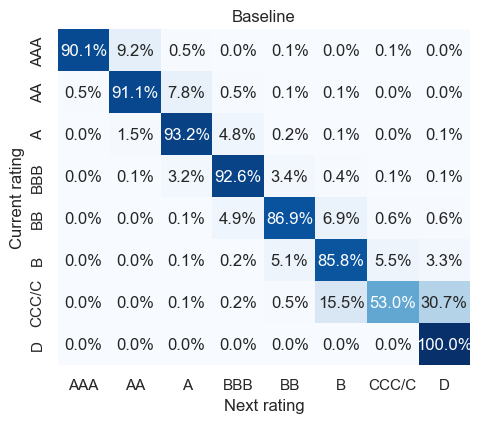

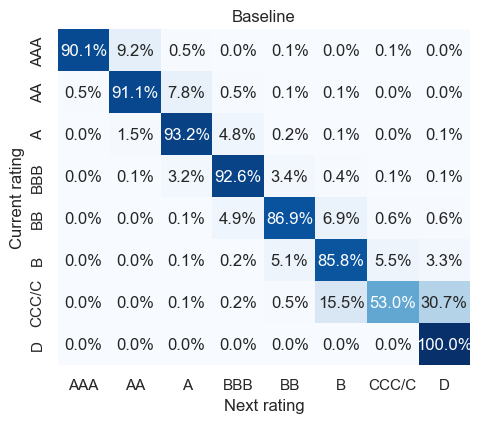

In [16]:
# Plot transition matrix heatmap
plot_matrices({"Baseline": P})

In [17]:
# Calculate multi-year default probabilities
baseline_pd = fixed_default_probabilities(P, HORIZONS)
baseline_pd.columns = [f"{h}-year" for h in HORIZONS]
display(baseline_pd.style.format("{:.2%}"))

,1-year,5-year,10-year,20-year
AAA,0.00%,0.14%,0.48%,1.81%
AA,0.02%,0.21%,0.68%,2.70%
A,0.05%,0.41%,1.30%,4.91%
BBB,0.15%,1.30%,3.94%,11.87%
BB,0.62%,5.94%,15.48%,32.85%
B,3.35%,22.15%,39.77%,59.10%
CCC/C,30.74%,66.96%,76.33%,84.28%
D,100.00%,100.00%,100.00%,100.00%


In [18]:
# Calculate expected time to default
baseline_chain = build_chain(P)
baseline_times = pd.Series(
    expected_times(baseline_chain["K"], baseline_chain["default_mask"]),
    index=RATINGS, name="Expected years to default"
)
display(baseline_times.to_frame().round(2))

,Expected years to default
AAA,137.58
AA,129.63
A,119.73
BBB,101.57
BB,68.79
B,40.19
CCC/C,16.64
D,0.00


#### Interpreting baseline results

The baseline transition matrix exhibits strong diagonal dominance, indicating that firms are generally more likely to retain their current credit rating than transition to another rating within a given year.

As expected, default probabilities increase as credit quality deteriorates. For example, a BB-rated firm has a one-year default probability of 0.62%, compared to 3.35% for a B-rated firm and 30.74% for a CCC/C-rated firm. Cumulative default probabilities also increase with the time horizon, reflecting the possibility of firms gradually migrating toward lower credit ratings before entering the absorbing default state.

The expected time to default decreases as credit quality deteriorates, ranging from 137.58 years for an AAA-rated firm to 16.64 years for a CCC/C-rated firm. These values represent theoretical expected hitting times under a time-homogeneous Markov chain rather than realistic forecasts of corporate lifespans.

The baseline model provides a benchmark against which the effects of economic regimes and rating momentum can be evaluated.

#### Defining economic regimes
Expansion and recession are annual regimes. Under the existing FRED loader, a year with at least one recession month is classified as recession.

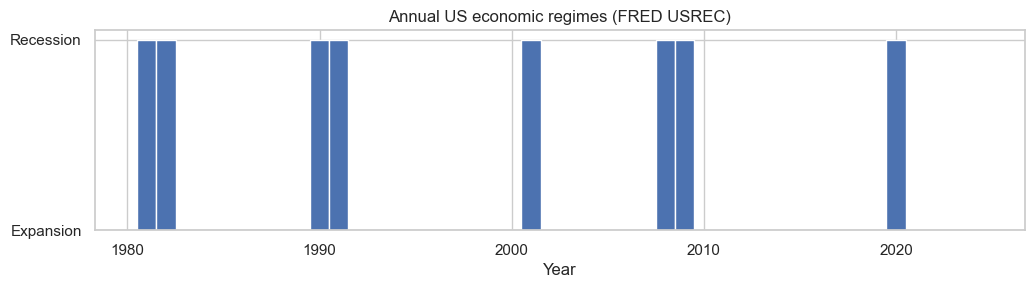

In [19]:
# Visualize historical recession periods
fig, ax = plt.subplots(figsize=(12, 2.6))
ax.bar(regime_series.index, regime_series.eq("recession").astype(int), width=1)
ax.set(yticks=[0, 1], yticklabels=["Expansion", "Recession"],
       xlabel="Year", title="Annual US economic regimes (FRED USREC)")
plt.show()

#### Economic multiplier estimation
We estimate regime-specific category multipliers by comparing historical rating activity by regime against the unconditional reference.

In [20]:
# Calculate the 8 economic multipliers
# Eight multipliers estimated from annual S&P activity joined to USREC.
alpha_raw = estimate_regime_multipliers(merged_data)
alpha = canonical_table(alpha_raw, REGIMES)

#### Adjusted transition probabilities
$P_{ij}^{(e)}=P_{ij}\alpha_{e,c(i,j)}/\sum_k P_{ik}\alpha_{e,c(i,k)}$.

In [21]:
# Construct expansion and recession matrices
# Use the original estimator output for compatibility with your existing module.
regime_matrices = {str(k).lower(): matrix_frame(v)
                   for k, v in build_regime_matrices(P, alpha_raw).items()}

In [22]:
# Validate both matrices
assert set(regime_matrices) == set(REGIMES)
for e, matrix in regime_matrices.items():
    validate_matrix(matrix)
    print(e, "passed")

expansion passed
recession passed


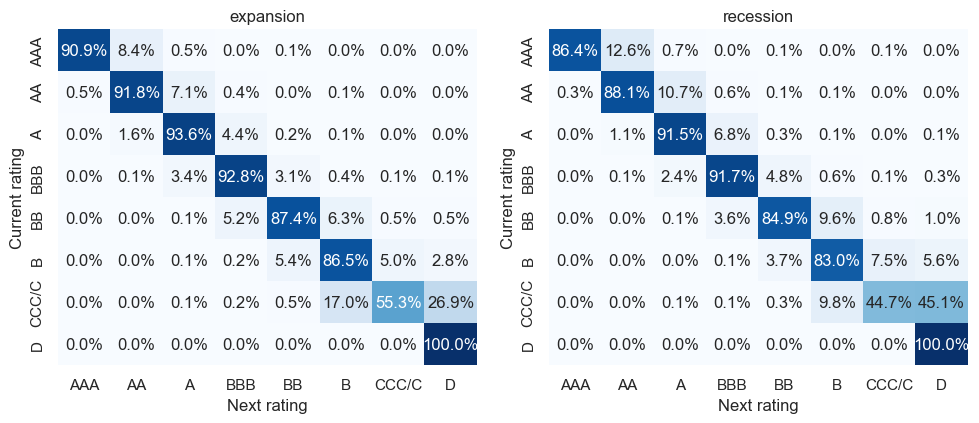

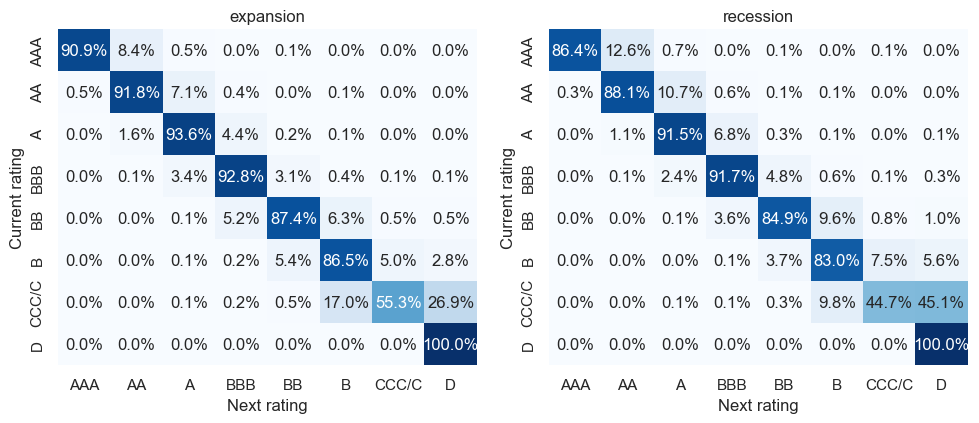

In [23]:
# Plot both matrix heatmaps
plot_matrices(regime_matrices)

In [25]:
# Calculate regime-specific default probabilities
# Conditional scenario: keep the chosen economic regime fixed for all years.
regime_pd = pd.concat({e: fixed_default_probabilities(M, HORIZONS)
                       for e, M in regime_matrices.items()}, axis=1)
display(regime_pd.style.format("{:.2%}"))

#### Interpreting regime effects

The regime-dependent model demonstrates that economic conditions can substantially influence credit rating transitions and default probabilities. During recessions, firms generally experience higher downgrade and default probabilities, while expansions are associated with greater rating stability and more favourable credit rating transitions.

For instance, the one-year default probability of a B-rated firm increases from 2.84% during an expansion to 5.62% during a recession. Similarly, the probability of default for a CCC/C-rated firm increases from 26.95% to 45.06%.

These differences become more pronounced over longer time horizons. Under a sustained expansion, a BB-rated firm has a 20-year cumulative default probability of 27.25%, compared to 56.97% under a sustained recession.

These results suggest that ignoring macroeconomic conditions can obscure substantial differences in conditional credit risk. However, the fixed-regime results should be interpreted as hypothetical economic scenarios rather than forecasts of future economic conditions.

#### Defining rating momentum
Momentum records whether the preceding rating movement was upward, unchanged, or downward.

#### Introduce Bangia et al.'s research
The conditional transition matrices are extracted from Bangia et al., Tables 4.2 and 4.3.

In [26]:
# Inspect extracted historical transition matrices
for label, matrix in historical_matrices.items():
    print(f"Bangia: {label}")
    display(pd.DataFrame(matrix).round(4))

Bangia: unconditional


,AAA,AA,A,BBB,BB,B,CCC/C,D
rating,,,,,,,,
AAA,0.9193,0.0746,0.0048,0.0008,0.0004,0.0000,0.0000,0.0000
AA,0.0064,0.9181,0.0675,0.0060,0.0006,0.0012,0.0003,0.0000
A,0.0007,0.0227,0.9169,0.0511,0.0056,0.0025,0.0001,0.0004
BBB,0.0004,0.0027,0.0556,0.8788,0.0483,0.0102,0.0017,0.0024
BB,0.0004,0.0010,0.0061,0.0775,0.8148,0.0789,0.0111,0.0101
B,0.0000,0.0010,0.0028,0.0046,0.0695,0.8280,0.0396,0.0545
CCC/C,0.0019,0.0000,0.0037,0.0075,0.0243,0.1213,0.6045,0.2369


Bangia: up


,AAA,AA,A,BBB,BB,B,CCC/C,D
rating,,,,,,,,
AAA,0.9245,0.0566,0.0189,0.0000,0.0000,0.0000,0.0000,0.0000
AA,0.0039,0.9533,0.0428,0.0000,0.0000,0.0000,0.0000,0.0000
A,0.0026,0.0129,0.9354,0.0491,0.0000,0.0000,0.0000,0.0000
BBB,0.0000,0.0000,0.0378,0.9012,0.0494,0.0087,0.0000,0.0029
BB,0.0000,0.0000,0.0138,0.0830,0.8581,0.0346,0.0069,0.0035
B,0.0000,0.0000,0.0196,0.0588,0.0588,0.8235,0.0196,0.0196
CCC/C,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Bangia: flat


,AAA,AA,A,BBB,BB,B,CCC/C,D
rating,,,,,,,,
AAA,0.9184,0.0758,0.0048,0.0005,0.0005,0.0000,0.0000,0.0000
AA,0.0058,0.9160,0.0702,0.0060,0.0007,0.0012,0.0000,0.0000
A,0.0006,0.0229,0.9156,0.0520,0.0060,0.0026,0.0000,0.0003
BBB,0.0006,0.0033,0.0596,0.8757,0.0453,0.0112,0.0023,0.0019
BB,0.0006,0.0013,0.0050,0.0911,0.8043,0.0760,0.0107,0.0110
B,0.0000,0.0016,0.0029,0.0042,0.0838,0.8082,0.0376,0.0617
CCC/C,0.0000,0.0000,0.0000,0.0077,0.0154,0.1231,0.7000,0.1538


Bangia: down


,AAA,AA,A,BBB,BB,B,CCC/C,D
rating,,,,,,,,
AAA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AA,0.0060,0.9048,0.0774,0.0060,0.0000,0.0060,0.0000,0.0000
A,0.0000,0.0093,0.9302,0.0512,0.0047,0.0023,0.0000,0.0023
BBB,0.0000,0.0018,0.0542,0.8590,0.0669,0.0127,0.0000,0.0054
BB,0.0000,0.0000,0.0112,0.0730,0.7921,0.0871,0.0169,0.0197
B,0.0000,0.0000,0.0024,0.0073,0.0605,0.7579,0.0799,0.0920
CCC/C,0.0052,0.0000,0.0105,0.0052,0.0419,0.0995,0.4293,0.4084


#### Momentum multiplier estimation
 We compare average conditional transition-category probabilities with the unconditional reference using the existing momentum estimator.

In [27]:
# Calculate the 12 momentum multipliers
# Twelve multipliers estimated from Bangia's historical conditional matrices.
beta_raw = estimate_momentum_multipliers(historical_matrices)
beta = canonical_table(beta_raw, MOMENTA)

In [28]:
# Display multiplier table
display(beta.loc[["down", "flat", "up"]].T.style.format("{:.3f}"))
# Compare the estimates to the previously extracted literature values.
reference = pd.DataFrame(
    [[.898, .974, 1.266, 1.772], [1.127, .992, .991, 1.111],
     [1.158, 1.026, .650, .386]],
    index=["down", "flat", "up"], columns=CATEGORIES
)
display((beta - reference).round(4))

momentum,down,flat,up
upgrade,0.898,1.127,1.158
unchanged,0.974,0.992,1.026
downgrade,1.266,0.991,0.650
default,1.771,1.111,0.386


,upgrade,unchanged,downgrade,default
momentum,,,,
down,-0.0002,0.0001,0.0001,-0.0005
flat,-0.0001,-0.0004,0.0001,0.0003
up,0.0004,0.0004,0.0002,-0.0002


#### Mathematical formulation
$P_{ij}^{(m)}=P_{ij}\beta_{m,c(i,j)}/\sum_k P_{ik}\beta_{m,c(i,k)}$.

In [29]:
# Construct three momentum matrices
momentum_matrices = {str(k).lower(): matrix_frame(v)
                     for k, v in build_momentum_matrices(P, beta_raw).items()}

In [30]:
# Validate transition matrices
assert set(momentum_matrices) == set(MOMENTA)
for m, matrix in momentum_matrices.items():
    validate_matrix(matrix)
    print(m, "passed")

up passed
flat passed
down passed


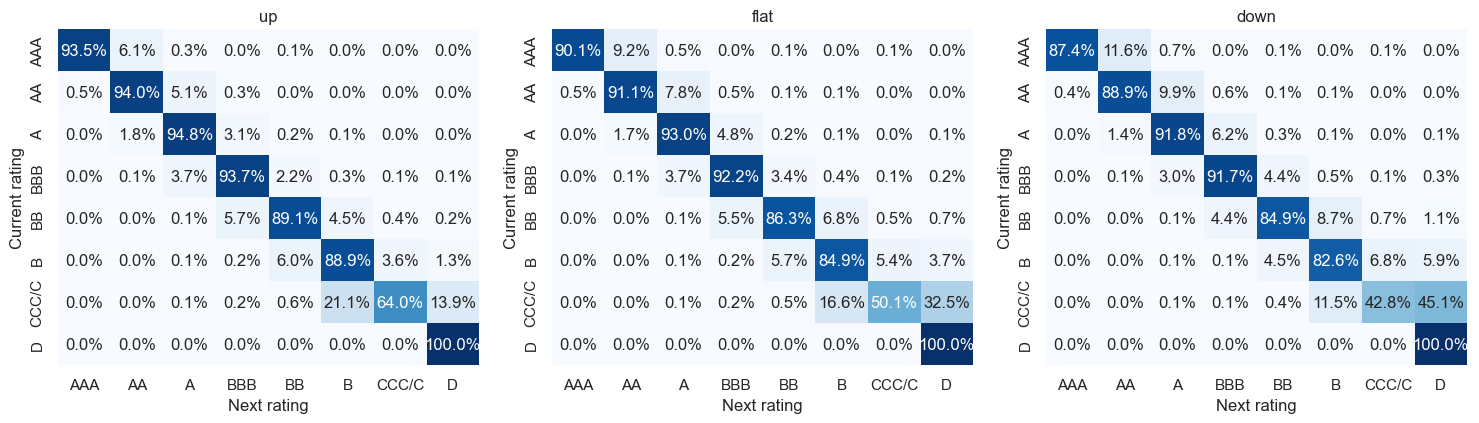

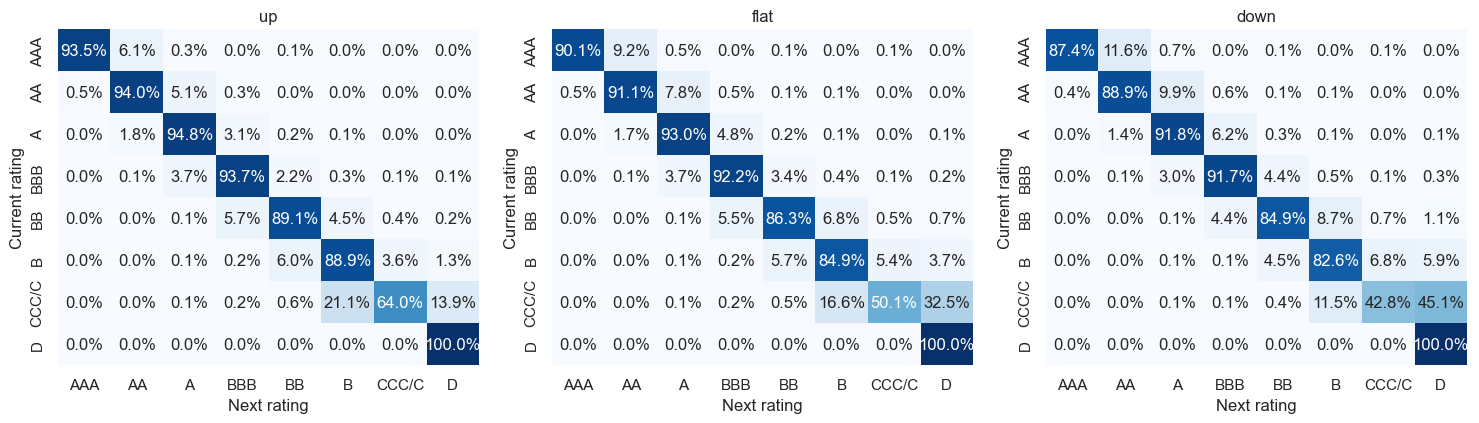

In [31]:
# Plot momentum matrix heatmaps
plot_matrices(momentum_matrices)

In [32]:
# Calculate momentum-specific default probabilities
# Momentum is an additional state; it changes after every transition.
momentum_chain = build_chain(P, momentum_matrices=momentum_matrices)
momentum_pd = pd.DataFrame({
    (m, h): [default_curve(momentum_chain["K"],
                           initial_index(momentum_chain, r, momentum=m),
                           momentum_chain["default_mask"], h)[-1] for r in RATINGS]
    for m in MOMENTA for h in HORIZONS
}, index=RATINGS)
display(momentum_pd.style.format("{:.2%}"))

#### Interpreting momentum effects

The momentum-dependent model demonstrates how previous credit rating movements can influence future transition probabilities. Firms that have recently experienced downgrades exhibit higher model-implied probabilities of subsequent downgrades and default, whereas recently upgraded firms generally exhibit more favourable transition probabilities.

For example, a B-rated firm with downward momentum has a one-year default probability of 5.85%, compared to 1.30% for a B-rated firm with upward momentum. Despite having identical current credit ratings, the recently downgraded firm has approximately 4.5 times the estimated default risk.

The relative influence of initial momentum decreases over longer time horizons as subsequent rating transitions update the momentum state. For B-rated firms, the ratio between downward and upward momentum default probabilities decreases from approximately 4.50 after one year to 1.05 after twenty years.

These results illustrate a limitation of modelling credit ratings as a first-order Markov chain using the current rating alone. By augmenting the state space to include momentum, historical dependence can be incorporated while preserving the first-order Markov property of the augmented process.

#### Combined model  and assumptions
$P_{ij}^{(e,m)}=P_{ij}\alpha_{e,c(i,j)}\beta_{m,c(i,j)}/\sum_kP_{ik}\alpha_{e,c(i,k)}\beta_{m,c(i,k)}$.


 We assume separability of economic-regime and momentum effects. This is a modeling assumption, not an empirically estimated interaction.

In [33]:
# Calculate 24 combined multipliers
# Multiplicative separability: gamma[e,m,c] = alpha[e,c] * beta[m,c].
combined_multipliers = combine_multipliers(alpha, beta)
assert combined_multipliers.shape == (6, 4)

In [34]:
# Display combined multiplier table
display(combined_multipliers.style.format("{:.3f}"))

In [35]:
# Construct six transition matrices
combined_matrices = build_combined_matrices(P, combined_multipliers)

In [36]:
# Validate all six matrices
assert set(combined_matrices) == {(e, m) for e in REGIMES for m in MOMENTA}
for (e, m), matrix in combined_matrices.items():
    validate_matrix(matrix)
    print(e, m, "passed")

expansion up passed
expansion flat passed
expansion down passed
recession up passed
recession flat passed
recession down passed


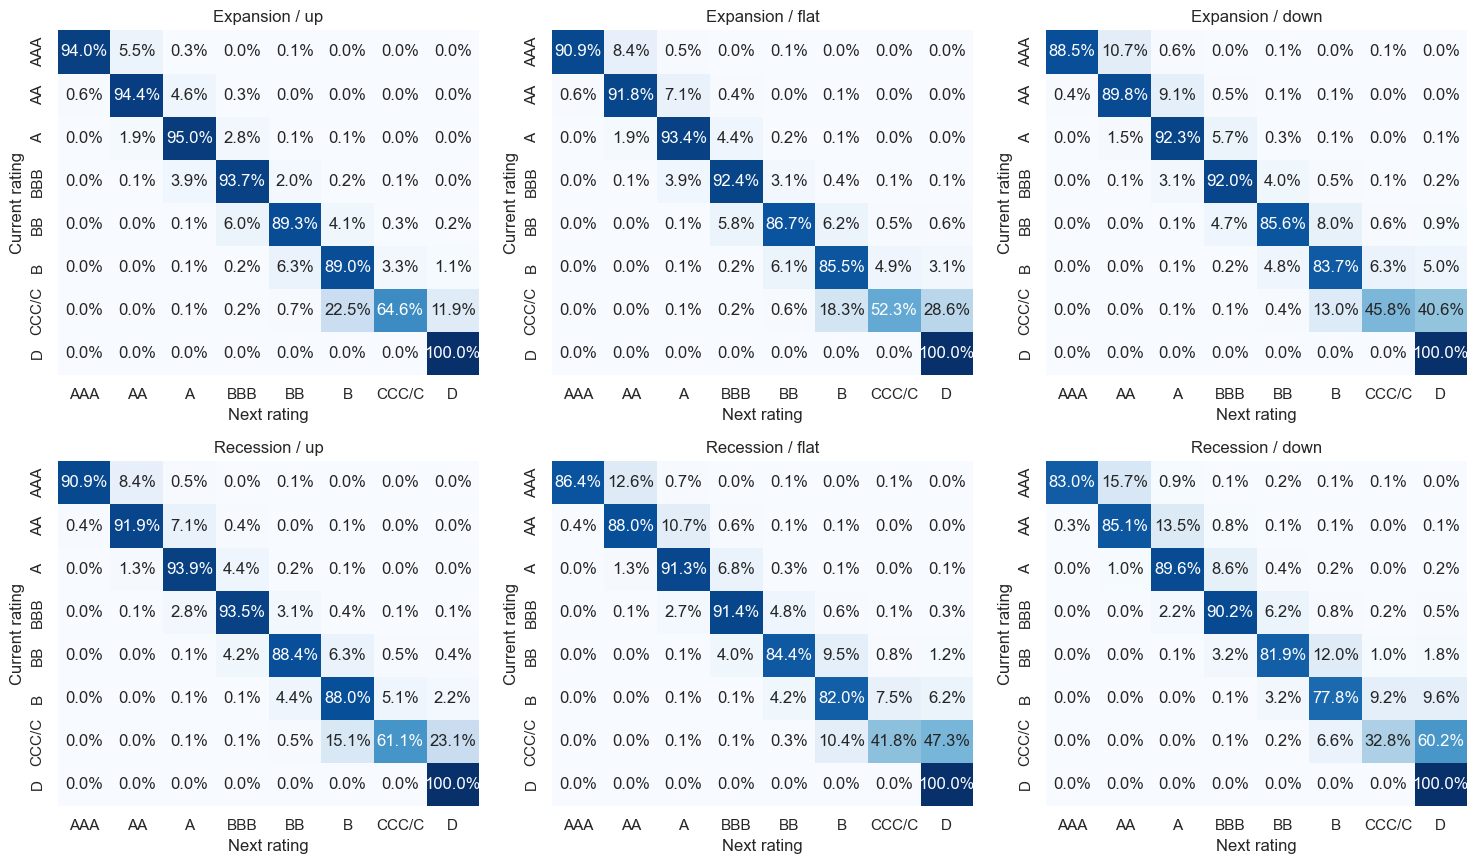

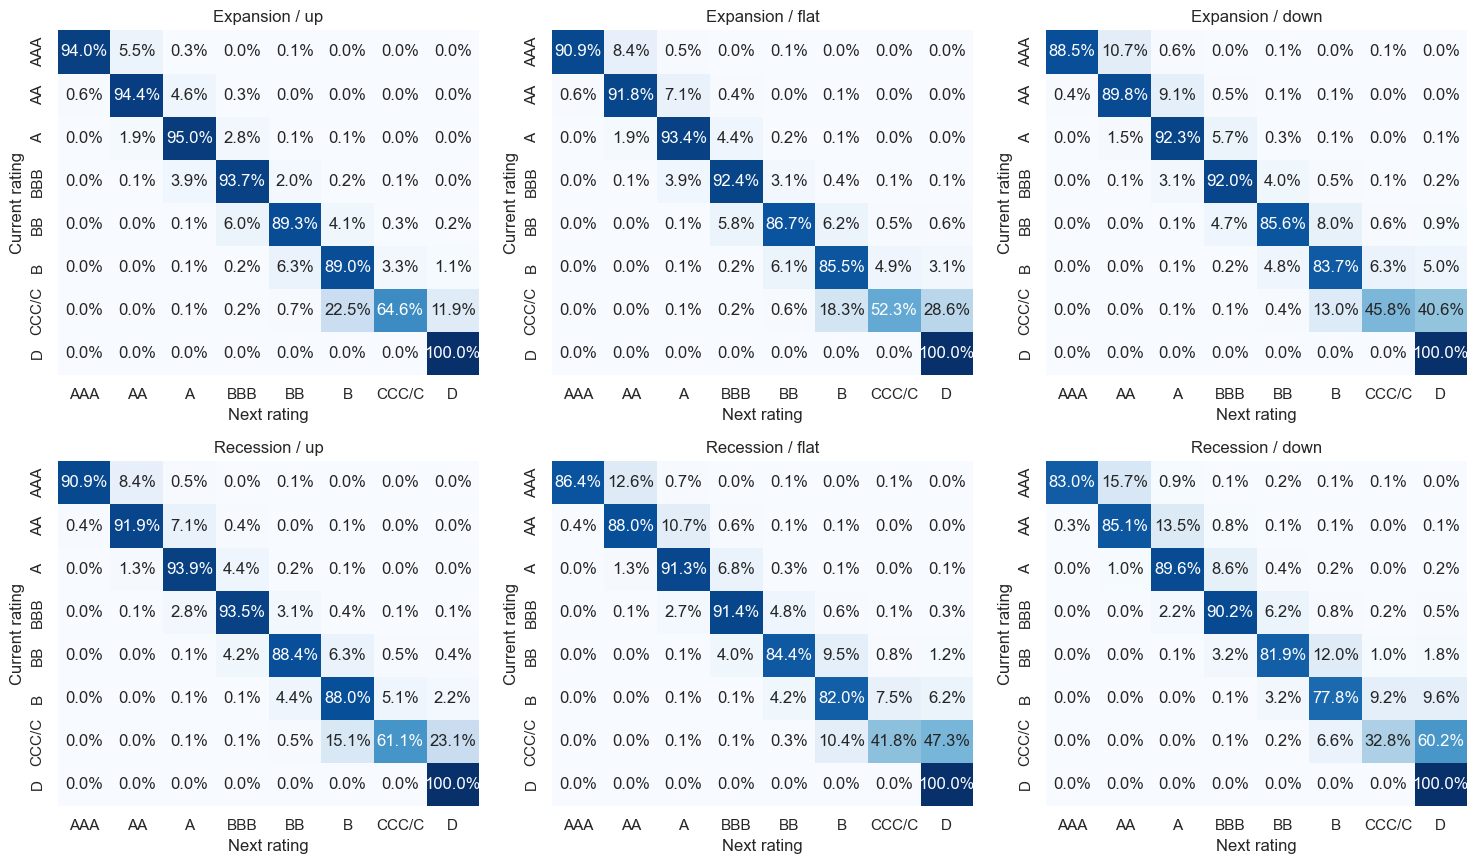

In [37]:
# Visualize all six matrices
plot_matrices({f"{e.title()} / {m}": combined_matrices[e, m]
               for e in REGIMES for m in MOMENTA})

In [38]:
# Calculate conditional default probabilities
# One-year default probabilities for each initial rating/regime/momentum.
combined_pd = pd.DataFrame({(e, m): M["D"]
                            for (e, m), M in combined_matrices.items()})
display(combined_pd.style.format("{:.2%}"))

#### Interpreting combined effects

The combined model incorporates both macroeconomic conditions and previous credit rating movements, providing a more granular representation of corporate credit risk. The six conditional transition matrices demonstrate how favourable and unfavourable economic conditions can reinforce or offset the effects of rating momentum.

For a B-rated firm, the one-year default probability ranges from 1.10% under an expansion with upward momentum to 9.60% under a recession with downward momentum. This represents approximately an 8.7-fold difference in default risk despite an identical current credit rating.

Interestingly, a B-rated firm experiencing downward momentum during an expansion has a default probability of 4.99%, compared to 2.24% for a firm experiencing upward momentum during a recession. This suggests that negative rating momentum can outweigh favourable macroeconomic conditions within the specified model.

The combined model therefore illustrates the importance of considering both economic conditions and firm-specific rating history when assessing credit risk. However, because the regime and momentum multipliers are estimated separately and combined multiplicatively, their joint effects are model-implied rather than independently estimated from jointly conditioned historical observations.

#### Monte Carlo methodology

We simulate annual transitions from the four models. The economic regime evolves according to a separately estimated two-state chain; momentum updates after each nondefault transition. Conditional on the current regime, the next regime is sampled independently of the rating transition.

In [39]:
# Configure simulation parameters
# Estimate an annual two-state Markov chain for the economic regime.
G = estimate_regime_transition(regimes)
print("Economic regime transition matrix")
display(G.style.format("{:.2%}"))

chains = {
    "Baseline": baseline_chain,
    "Regime": build_chain(P, regime_matrices=regime_matrices, G=G),
    "Momentum": momentum_chain,
    "Combined": build_chain(P, combined_matrices=combined_matrices, G=G)
}
initials = {name: initial_index(chain, INITIAL_RATING, INITIAL_REGIME, INITIAL_MOMENTUM)
            for name, chain in chains.items()}
paths = {}
# Independent reproducible random streams for all four models.
seeds = dict(zip(chains, np.random.SeedSequence(RANDOM_SEED).spawn(len(chains))))

Economic regime transition matrix


,expansion,recession
expansion,88.57%,11.43%
recession,62.50%,37.50%


In [40]:
# Simulate baseline model
paths["Baseline"] = simulate_paths(
    chains["Baseline"], initials["Baseline"], N_SIMULATIONS, TIME_HORIZON, seeds["Baseline"]
)
print(paths["Baseline"].shape)  # (simulated firms, years including year 0)

(10000, 21)


In [41]:
# Simulate economic regime model
paths["Regime"] = simulate_paths(
    chains["Regime"], initials["Regime"], N_SIMULATIONS, TIME_HORIZON, seeds["Regime"]
)
print(paths["Regime"].shape)  # (simulated firms, years including year 0)

(10000, 21)


In [42]:
# Simulate momentum model
paths["Momentum"] = simulate_paths(
    chains["Momentum"], initials["Momentum"], N_SIMULATIONS, TIME_HORIZON, seeds["Momentum"]
)
print(paths["Momentum"].shape)  # (simulated firms, years including year 0)

(10000, 21)


In [43]:
# Simulate combined model
paths["Combined"] = simulate_paths(
    chains["Combined"], initials["Combined"], N_SIMULATIONS, TIME_HORIZON, seeds["Combined"]
)
print(paths["Combined"].shape)  # (simulated firms, years including year 0)

(10000, 21)


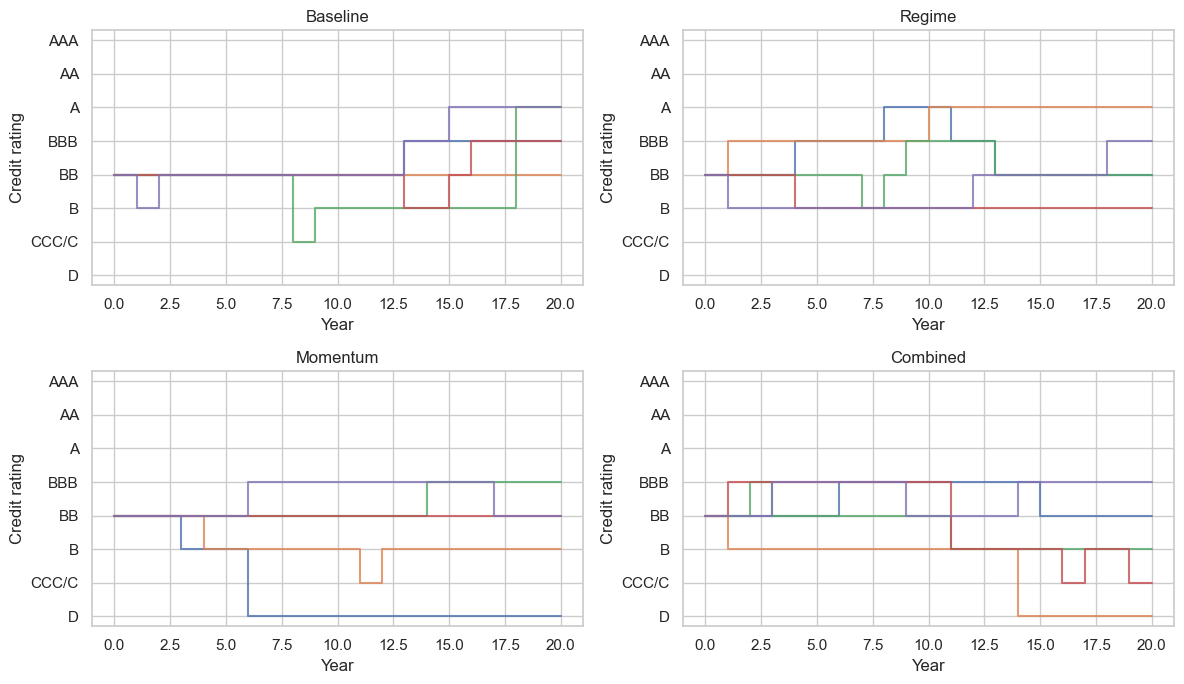

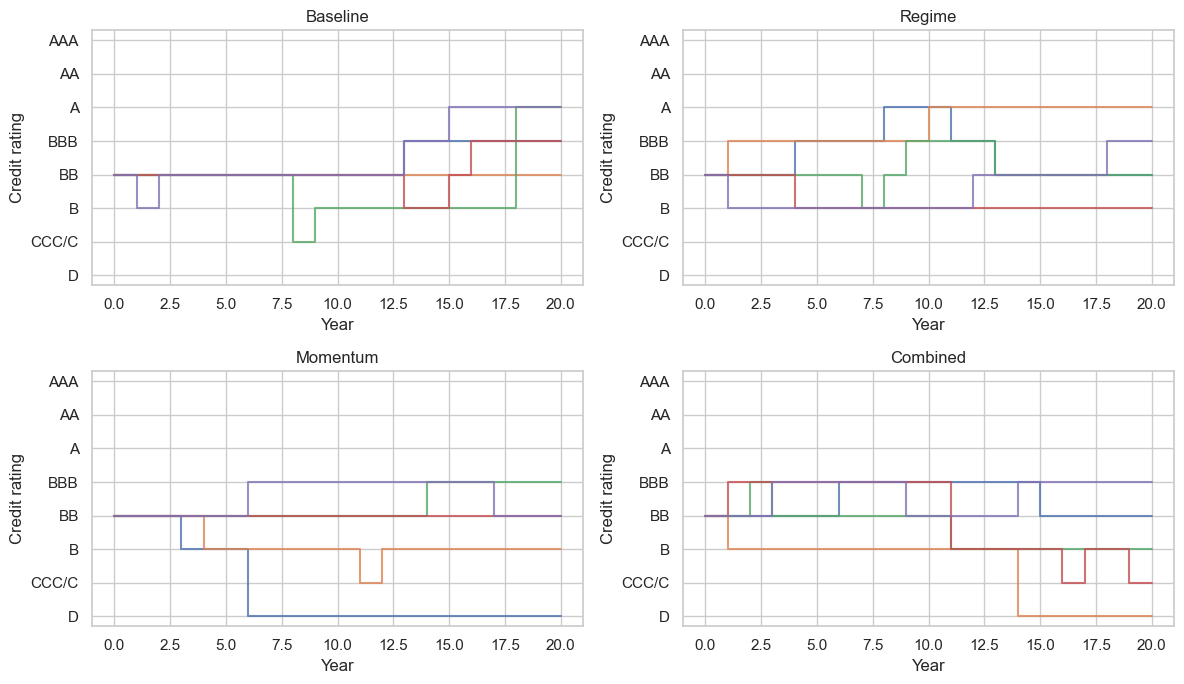

In [44]:
# Plot sample credit rating trajectories
plot_paths(paths, n_paths=5)

In [45]:
# Calculate empirical default probabilities
empirical = pd.DataFrame({name: empirical_curve(p) for name, p in paths.items()})
empirical.index.name = "Year"
display(empirical.loc[HORIZONS].style.format("{:.2%}"))

,Baseline,Regime,Momentum,Combined
Year,,,,
1,0.62%,0.54%,0.87%,0.51%
5,6.00%,5.23%,6.99%,6.90%
10,15.60%,14.35%,17.71%,16.71%
20,32.43%,30.97%,34.88%,33.94%


In [46]:
# Analyze time to default
default_times = {name: time_to_default(p) for name, p in paths.items()}
# Nondefaults are right-censored; do not treat them as zero or discard them
# when estimating the restricted mean E[min(T_D, H)].
censoring = pd.DataFrame({name: {
    "Defaults observed": int(np.isfinite(t).sum()),
    "Censored paths": int(np.isinf(t).sum()),
    "Restricted mean years": np.minimum(t, TIME_HORIZON).mean()
} for name, t in default_times.items()}).T
display(censoring.round(3))

,Defaults observed,Censored paths,Restricted mean years
Baseline,3243.0,6757.0,17.057
Regime,3097.0,6903.0,17.280
Momentum,3488.0,6512.0,16.704
Combined,3394.0,6606.0,16.849


#### Interpreting simulation results

Monte Carlo simulations were conducted using 10,000 credit rating trajectories over a 20-year time horizon, with each firm initially assigned a BB credit rating.

The simulated 20-year cumulative default probabilities were 32.43%, 30.97%, 34.88%, and 33.94% for the baseline, regime-dependent, momentum-dependent, and combined models, respectively.

Interestingly, the momentum-dependent model produced the highest cumulative default probability, while the regime-dependent model produced the lowest. The latter result is consistent with the predominance of expansionary periods in the historical economic regime data. Incorporating additional risk factors does not necessarily increase default probabilities, since favourable economic conditions can partially offset adverse rating momentum.

The simulated default probabilities closely approximate their analytical counterparts, supporting the numerical consistency of the model implementations and illustrating the law of large numbers.

Furthermore, trajectories that did not reach default within the simulation horizon were treated as right-censored observations. The restricted mean time to default was lowest under the momentum-dependent model and highest under the regime-dependent model, consistent with their respective cumulative default probabilities.

#### Comparison metrics
We compare cumulative default probabilities, exact mean time to default, and restricted means using identical initial conditions. Predictive likelihood and AIC require shared observed transition data not yet available.

In [47]:
# Compare one-year default probabilities
# Exact probabilities from the appropriately augmented transition matrix.
analytical = pd.DataFrame({name: default_curve(chain["K"], initials[name],
                                              chain["default_mask"], TIME_HORIZON)
                           for name, chain in chains.items()})
analytical.index.name = "Year"
display(analytical.loc[[1]].T.rename(columns={1: "1-year PD"}).style.format("{:.2%}"))

Year,1-year PD
Baseline,0.62%
Regime,0.52%
Momentum,0.69%
Combined,0.58%


In [48]:
# Compare five-year default probabilities
display(analytical.loc[[5]].T.rename(columns={5: "5-year PD"}).style.format("{:.2%}"))

Year,5-year PD
Baseline,5.94%
Regime,5.53%
Momentum,7.27%
Combined,6.76%


In [49]:
# Compare ten-year default probabilities
display(analytical.loc[[10]].T.rename(columns={10: "10-year PD"}).style.format("{:.2%}"))

Year,10-year PD
Baseline,15.48%
Regime,14.69%
Momentum,17.68%
Combined,16.78%


In [50]:
# Compare expected time to default
exact_times = pd.Series({name: expected_times(chain["K"], chain["default_mask"])[initials[name]]
                         for name, chain in chains.items()}, name="Expected years to default")
# Compare restricted means over the same finite horizon as simulations.
restricted_exact = (1 - analytical.iloc[:-1]).sum(axis=0).rename("Exact restricted mean years")
display(pd.concat([exact_times, restricted_exact, censoring["Restricted mean years"]], axis=1).round(3))

,Expected years to default,Exact restricted mean years,Restricted mean years
Baseline,68.785,17.051,17.057
Regime,72.160,17.193,17.280
Momentum,70.478,16.716,16.704
Combined,74.043,16.874,16.849


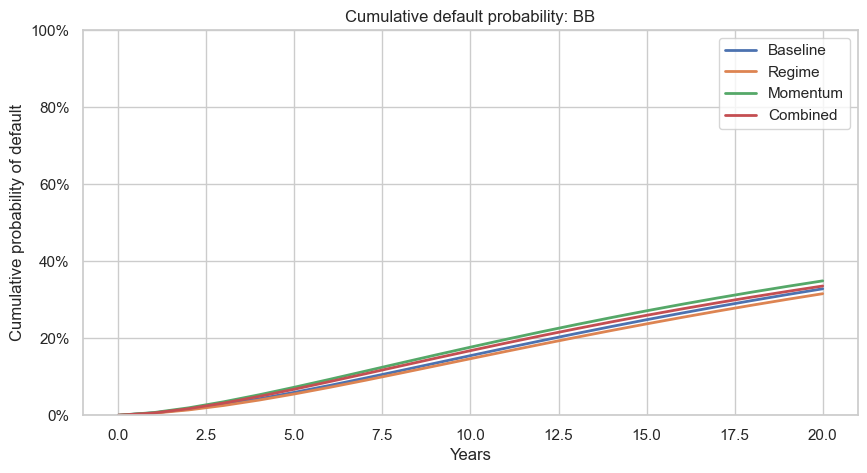

In [51]:
# Plot cumulative default probability curves
ax = analytical.plot(figsize=(10, 5), linewidth=2)
ax.set(xlabel="Years", ylabel="Cumulative probability of default",
       title=f"Cumulative default probability: {INITIAL_RATING}", ylim=(0, 1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.show()

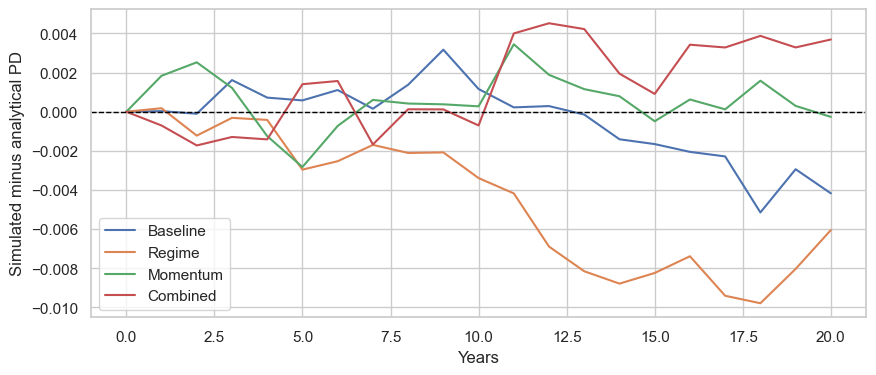

In [52]:
# Compare analytical and simulated results
# Monte Carlo sampling error is measured against the exact model probabilities.
comparison = pd.concat({"Analytical": analytical.loc[HORIZONS],
                        "Simulated": empirical.loc[HORIZONS],
                        "Absolute error": (analytical - empirical).abs().loc[HORIZONS]}, axis=1)
display(comparison.style.format("{:.3%}"))
ax = (empirical - analytical).plot(figsize=(10, 4))
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set(xlabel="Years", ylabel="Simulated minus analytical PD")
plt.show()

,1-year PD,5-year PD,10-year PD,20-year PD
Multiplier strength,,,,
0.000000,0.62%,5.94%,15.48%,32.85%
0.500000,0.60%,6.28%,15.99%,32.99%
1.000000,0.58%,6.76%,16.78%,33.57%
1.500000,0.56%,7.40%,17.87%,34.56%
2.000000,0.54%,8.21%,19.26%,35.94%


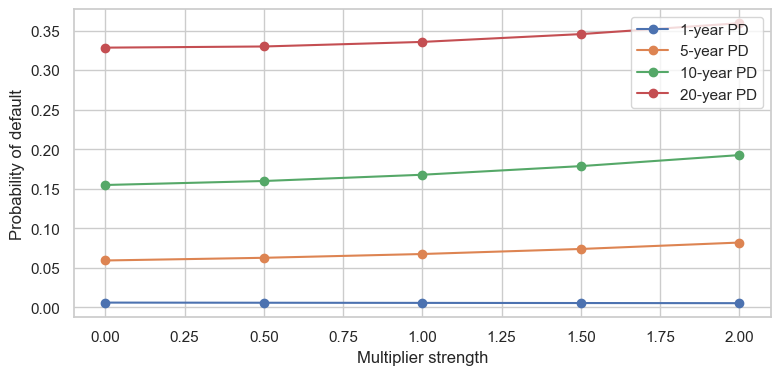

In [53]:
# Sensitivity analysis of multipliers
# Sensitivity: power-transform the positive multiplier tables.
# Strength 0 removes both effects; strength 1 is the estimated combined model.
sensitivity = {}
for strength in [0, 0.5, 1, 1.5, 2]:
    weights = combine_multipliers(alpha.pow(strength), beta.pow(strength))
    matrices = build_combined_matrices(P, weights)
    chain = build_chain(P, combined_matrices=matrices, G=G)
    initial = initial_index(chain, INITIAL_RATING, INITIAL_REGIME, INITIAL_MOMENTUM)
    curve = default_curve(chain["K"], initial, chain["default_mask"], TIME_HORIZON)
    sensitivity[strength] = {f"{h}-year PD": curve[h] for h in HORIZONS}
sensitivity_table = pd.DataFrame(sensitivity).T
sensitivity_table.index.name = "Multiplier strength"
display(sensitivity_table.style.format("{:.2%}"))
ax = sensitivity_table.plot(marker="o", figsize=(9, 4))
ax.set(ylabel="Probability of default", xlabel="Multiplier strength")
plt.show()

In [54]:
# Generate final results summary table
summary = pd.DataFrame({
    "1-year PD": analytical.loc[1],
    "5-year PD": analytical.loc[5],
    "10-year PD": analytical.loc[10],
    "20-year PD": analytical.loc[20],
    "Expected years to default": exact_times,
    "20-year restricted mean (exact)": restricted_exact,
    "20-year restricted mean (MC)": censoring["Restricted mean years"]
})
formats = {c: "{:.2%}" if c.endswith("PD") else "{:.2f}" for c in summary.columns}
display(summary.style.format(formats))
PROCESSED.mkdir(parents=True, exist_ok=True)
summary.to_csv(PROCESSED / "model_comparison.csv")

,1-year PD,5-year PD,10-year PD,20-year PD,Expected years to default,20-year restricted mean (exact),20-year restricted mean (MC)
Baseline,0.62%,5.94%,15.48%,32.85%,68.79,17.05,17.06
Regime,0.52%,5.53%,14.69%,31.57%,72.16,17.19,17.28
Momentum,0.69%,7.27%,17.68%,34.91%,70.48,16.72,16.70
Combined,0.58%,6.76%,16.78%,33.57%,74.04,16.87,16.85


## Historical Model Evaluation

In this section, we evaluate the predictive performance of
the four existing credit rating transition models using
historical corporate credit rating data from Fitch Ratings.

Each model is initialized using observed historical credit
ratings, economic conditions and credit rating momentum.

Monte Carlo simulations are used to estimate annual default
rates, which are compared against actual historical default
rates.

The models are evaluated using RMSE, MAE, Brier Score and
Negative Log-Likelihood.

No transition matrices or multipliers are re-estimated
during this experiment.

In [55]:
# Load historical Fitch corporate rating actions

FITCH_PATH = RAW / "fitch_corporate_ratings.csv"

fitch_raw = pd.read_csv(
    FITCH_PATH,
    dtype=str,
    low_memory=False
)

fitch_raw.columns = (
    fitch_raw.columns.str.strip().str.lower()
)

print("Number of records:", len(fitch_raw))
print("Available columns:", fitch_raw.columns.tolist())

display(fitch_raw.head())

Number of records: 126744
Available columns: ['rating_agency_name', 'file_creating_date', 'sec_category', 'issuer_name', 'legal_entity_identifier', 'object_type_rated', 'instrument_name', 'cusip_number', 'coupon_date', 'maturity_date', 'par_value', 'issued_paid', 'rating', 'rating_action_date', 'rating_action_class', 'rating_type', 'rating_sub_type', 'rating_type_term', 'other_announcement_type', 'watch_status', 'rating_outlook', 'issuer_identifier', 'issuer_identifier_schema', 'instrument_identifier', 'instrument_identifier_schema', 'central_index_key', 'obligor_identifier', 'obligor_identifier_schema', 'obligor_identifier_other', 'obligor_sec_category', 'obligor_industry_group', 'obligor_name']


,rating_agency_name,file_creating_date,sec_category,issuer_name,legal_entity_identifier,object_type_rated,instrument_name,cusip_number,coupon_date,maturity_date,par_value,issued_paid,rating,rating_action_date,rating_action_class,...,rating_type_term,other_announcement_type,watch_status,rating_outlook,issuer_identifier,issuer_identifier_schema,instrument_identifier,instrument_identifier_schema,central_index_key,obligor_identifier,obligor_identifier_schema,obligor_identifier_other,obligor_sec_category,obligor_industry_group,obligor_name
0,Fitch Ratings,2026-11-01,Corporate,"""AngloGold Ashanti Holdings Plc""",NaN,Instrument,"""AngloGold Ashanti Holdings Plc USD 700 mln 3....",03512TAE1,NaN,NaN,NaN,true,BBB-,2020-10-01,NW,...,NaN,NaN,NaN,NaN,97010405,NRSRO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Fitch Ratings,2026-11-01,Corporate,"""AngloGold Ashanti Holdings Plc""",NaN,Instrument,"""AngloGold Ashanti Holdings Plc USD 750 mln 3....",03512TAF8,NaN,NaN,NaN,true,BBB-,2021-10-18,NW,...,NaN,NaN,NaN,NaN,97010405,NRSRO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Fitch Ratings,2026-11-01,NaN,NaN,5493001QYTIDILBVYO18,NaN,NaN,NaN,NaN,NaN,NaN,true,BBB,2012-06-15,HS,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Corporate,NaN,"""Companhia Brasileira de Aluminio"""
3,Fitch Ratings,2026-11-01,NaN,NaN,5493001QYTIDILBVYO18,NaN,NaN,NaN,NaN,NaN,NaN,true,WD,2014-08-25,WO,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Corporate,NaN,"""Companhia Brasileira de Aluminio"""
4,Fitch Ratings,2026-11-01,Corporate,"""Dalian Wanda Commercial Management Group Co.,...",NaN,Instrument,"""Dalian Wanda Commercial Management Group Co.,...",NaN,NaN,NaN,NaN,true,BBB+,2013-10-29,NW,...,NaN,NaN,NaN,NaN,92897333,NRSRO,93102692,NRSRO,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [56]:
# Standardize Fitch credit rating actions

BT_RATINGS = list(P.index)

LOW_RATING = next(
    r for r in BT_RATINGS if r.startswith("CCC")
)

RATING_INDEX = {
    rating: i for i, rating in enumerate(BT_RATINGS)
}


def standardize_fitch_rating(rating):

    if pd.isna(rating):
        return np.nan

    rating = rating.strip().upper()

    if rating in ["RD", "D"]:
        return "D"

    if rating in ["WD", "NR"]:
        return "WD"

    if rating.startswith("CCC") or rating in ["CC", "C"]:
        return LOW_RATING

    rating = rating.rstrip("+-")

    return rating if rating in BT_RATINGS else np.nan


# Keep issuer-level long-term credit ratings
fitch = fitch_raw.loc[
    fitch_raw["rating_type"].str.strip().str.lower()
    == "long term issuer default rating"
].copy()

fitch = fitch.rename(columns={
    "obligor_name": "issuer_id",
    "rating_action_date": "date"
})

fitch["date"] = pd.to_datetime(
    fitch["date"], errors="coerce"
)

fitch["rating"] = fitch["rating"].map(
    standardize_fitch_rating
)

# Preserve unknown ratings as gaps in rating coverage
fitch["rating"] = fitch["rating"].fillna("UNKNOWN")

fitch = (
    fitch[["issuer_id", "date", "rating"]]
    .dropna()
    .drop_duplicates()
    .sort_values(["issuer_id", "date"], kind="stable")
    .reset_index(drop=True)
)

print("Rating actions:", len(fitch))
print("Unique issuers:", fitch["issuer_id"].nunique())
print("Date range:", fitch["date"].min(), fitch["date"].max())

display(fitch.head(10))
display(fitch["rating"].value_counts())

Rating actions: 13278
Unique issuers: 4403
Date range: 2003-09-04 00:00:00 2025-10-31 00:00:00


,issuer_id,date,rating
0,"""11065220 Canada, Inc.""",2021-08-18,B
1,"""11065220 Canada, Inc.""",2022-06-27,CCC/C
2,"""11065220 Canada, Inc.""",2022-07-05,CCC/C
3,"""11065220 Canada, Inc.""",2022-07-20,D
4,"""11065220 Canada, Inc.""",2022-07-20,CCC/C
5,"""11065220 Canada, Inc.""",2022-10-28,CCC/C
6,"""11065220 Canada, Inc.""",2023-07-06,D
7,"""11065220 Canada, Inc.""",2023-07-06,CCC/C
8,"""11065220 Canada, Inc.""",2023-07-18,D
9,"""11065220 Canada, Inc.""",2023-07-18,CCC/C


rating
BBB      3090
B        2798
BB       2570
WD       2090
CCC/C    1281
A         941
D         420
AA         85
AAA         3
Name: count, dtype: int64

In [57]:
# Reconstruct annual historical credit rating transitions

BACKTEST_START = 2016
BACKTEST_END = 2023

historical_records = []

for issuer, group in fitch.groupby("issuer_id"):

    dates = group["date"].to_numpy(dtype="datetime64[ns]")
    ratings = group["rating"].to_numpy()

    for year in range(BACKTEST_START, BACKTEST_END + 1):

        previous_date = np.datetime64(f"{year - 1}-01-01")
        current_date = np.datetime64(f"{year}-01-01")
        next_date = np.datetime64(f"{year + 1}-01-01")

        # Locate the ratings immediately before each date
        previous_idx = np.searchsorted(dates, previous_date) - 1
        current_idx = np.searchsorted(dates, current_date) - 1
        next_idx = np.searchsorted(dates, next_date) - 1

        if previous_idx < 0 or current_idx < 0:
            continue

        previous_rating = ratings[previous_idx]
        current_rating = ratings[current_idx]

        # Exclude companies without valid initial ratings
        if previous_rating not in BT_RATINGS:
            continue

        if current_rating not in BT_RATINGS:
            continue

        # Default is absorbing in our models
        if "D" in ratings[:current_idx + 1]:
            continue

        # Require continuous rating coverage for momentum
        prior_actions = ratings[previous_idx + 1:current_idx + 1]

        if np.isin(prior_actions, ["WD", "UNKNOWN"]).any():
            continue

        # Examine rating actions during the forecast year
        yearly_actions = ratings[current_idx + 1:next_idx + 1]

        next_rating = ratings[next_idx]

        # Stop at the first default or interruption in coverage
        for rating in yearly_actions:
            if rating in ["D", "WD", "UNKNOWN"]:
                next_rating = rating
                break

        # Exclude censored or withdrawn observations
        if next_rating not in BT_RATINGS:
            continue

        historical_records.append({
            "issuer_id": issuer,
            "year": year,
            "previous_rating": previous_rating,
            "current_rating": current_rating,
            "next_rating": next_rating
        })

historical = pd.DataFrame(historical_records)

assert not historical.empty, "No usable historical transitions"

print("Historical observations:", len(historical))
print("Unique companies:", historical["issuer_id"].nunique())

display(historical.head(10))

Historical observations: 12343
Unique companies: 2734


,issuer_id,year,previous_rating,current_rating,next_rating
0,"""361 Degrees International Limited""",2018,BB,BB,BB
1,"""361 Degrees International Limited""",2019,BB,BB,BB
2,"""361 Degrees International Limited""",2020,BB,BB,B
3,"""361 Degrees International Limited""",2021,BB,B,B
4,"""A.I. Candelaria (Spain), S.A.""",2020,BBB,BBB,BB
5,"""A.I. Candelaria (Spain), S.A.""",2021,BBB,BB,BB
6,"""A.I. Candelaria (Spain), S.A.""",2022,BB,BB,BB
7,"""A.I. Candelaria (Spain), S.A.""",2023,BB,BB,BB
8,"""AB SKF""",2020,BBB,BBB,BBB
9,"""AB SKF""",2021,BBB,BBB,BBB


In [58]:
# Calculate historical credit rating momentum

previous = historical["previous_rating"].map(RATING_INDEX)
current = historical["current_rating"].map(RATING_INDEX)

historical["momentum"] = np.select(
    [
        current < previous,
        current > previous
    ],
    [
        "up",
        "down"
    ],
    default="flat"
)

# Assign economic regimes using existing FRED data
# Use the previous year's regime as a forecasting proxy

bt_regimes = annual_regime_series(regimes)

bt_regimes.index = bt_regimes.index.astype(int)

historical["regime"] = (
    historical["year"] - 1
).map(bt_regimes)

historical = historical.dropna(
    subset=["regime"]
).reset_index(drop=True)

# Identify actual historical defaults
historical["defaulted"] = (
    historical["next_rating"] == "D"
).astype(int)

assert not historical.empty

display(historical.head(10))

# Save processed historical transitions
PROCESSED.mkdir(parents=True, exist_ok=True)

historical.to_csv(
    PROCESSED / "historical_rating_transitions.csv",
    index=False
)

,issuer_id,year,previous_rating,current_rating,next_rating,momentum,regime,defaulted
0,"""361 Degrees International Limited""",2018,BB,BB,BB,flat,expansion,0
1,"""361 Degrees International Limited""",2019,BB,BB,BB,flat,expansion,0
2,"""361 Degrees International Limited""",2020,BB,BB,B,flat,expansion,0
3,"""361 Degrees International Limited""",2021,BB,B,B,down,recession,0
4,"""A.I. Candelaria (Spain), S.A.""",2020,BBB,BBB,BB,flat,expansion,0
5,"""A.I. Candelaria (Spain), S.A.""",2021,BBB,BB,BB,down,recession,0
6,"""A.I. Candelaria (Spain), S.A.""",2022,BB,BB,BB,flat,expansion,0
7,"""A.I. Candelaria (Spain), S.A.""",2023,BB,BB,BB,flat,expansion,0
8,"""AB SKF""",2020,BBB,BBB,BBB,flat,expansion,0
9,"""AB SKF""",2021,BBB,BBB,BBB,flat,recession,0


,Companies,Defaults,Actual_PD
year,,,
2016,1390,21,1.51%
2017,1395,10,0.72%
2018,1394,13,0.93%
2019,1485,20,1.35%
2020,1586,38,2.40%
2021,1631,19,1.16%
2022,1619,23,1.42%
2023,1843,25,1.36%


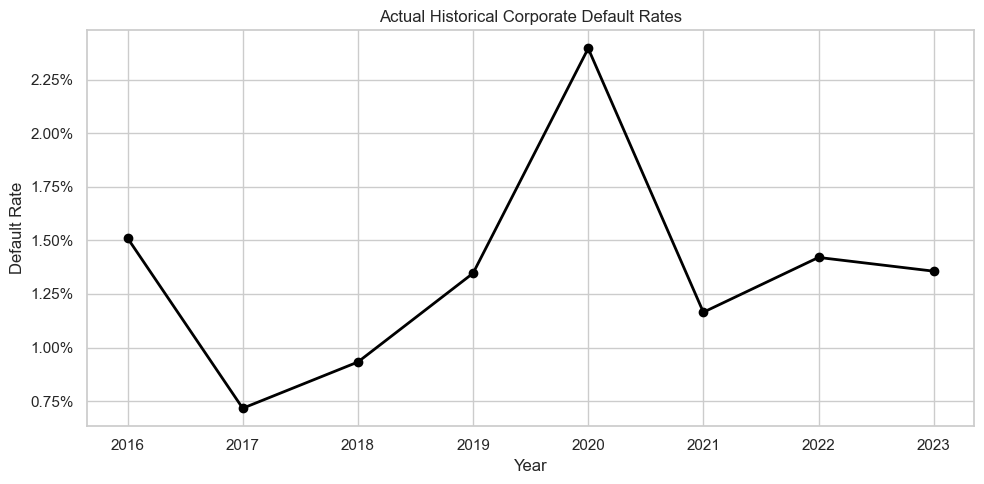

In [59]:
# Calculate actual historical annual default rates

actual_history = historical.groupby("year").agg(
    Companies=("issuer_id", "count"),
    Defaults=("defaulted", "sum"),
    Actual_PD=("defaulted", "mean")
)

display(
    actual_history.style.format({
        "Actual_PD": "{:.2%}"
    })
)

ax = actual_history["Actual_PD"].plot(
    figsize=(10, 5),
    marker="o",
    color="black",
    linewidth=2
)

ax.set_title("Actual Historical Corporate Default Rates")
ax.set_xlabel("Year")
ax.set_ylabel("Default Rate")

ax.yaxis.set_major_formatter(
    plt.matplotlib.ticker.PercentFormatter(1)
)

plt.tight_layout()
plt.show()

In [60]:
# Retrieve transition probabilities from the existing models

BACKTEST_MODELS = [
    "Baseline",
    "Regime",
    "Momentum",
    "Combined"
]


def get_model_probabilities(model, rating, regime, momentum):

    if model == "Baseline":
        matrix = P

    elif model == "Regime":
        matrix = regime_matrices[regime]

    elif model == "Momentum":
        matrix = momentum_matrices[momentum]

    elif model == "Combined":
        matrix = combined_matrices[(regime, momentum)]

    else:
        raise ValueError(f"Unknown model: {model}")

    return matrix.loc[rating, BT_RATINGS].to_numpy(
        dtype=float
    )

In [61]:
# Perform historical Monte Carlo simulations

BACKTEST_SIMULATIONS = 10_000

rng = np.random.default_rng(RANDOM_SEED)

backtest_records = []

default_idx = RATING_INDEX["D"]

for year, cohort in historical.groupby("year"):

    n_companies = len(cohort)

    actual_pd = cohort["defaulted"].mean()

    for model in BACKTEST_MODELS:

        simulated_defaults = np.zeros(
            BACKTEST_SIMULATIONS,
            dtype=int
        )

        brier_sum = 0.0
        nll_sum = 0.0
        expected_defaults = 0.0

        # Group companies sharing identical initial conditions
        groups = cohort.groupby([
            "current_rating",
            "regime",
            "momentum"
        ])

        for (rating, regime, momentum), group in groups:

            probabilities = get_model_probabilities(
                model,
                rating,
                regime,
                momentum
            )

            p_default = probabilities[default_idx]

            # Simulate independent defaults within the group
            simulated_defaults += rng.binomial(
                n=len(group),
                p=p_default,
                size=BACKTEST_SIMULATIONS
            )

            expected_defaults += len(group) * p_default

            # Calculate Brier Score against actual outcomes
            brier_sum += np.sum(
                (p_default - group["defaulted"].to_numpy()) ** 2
            )

            # Calculate likelihood of actual rating transitions
            observed_indices = (
                group["next_rating"]
                .map(RATING_INDEX)
                .to_numpy(dtype=int)
            )

            observed_probabilities = probabilities[
                observed_indices
            ]

            with np.errstate(divide="ignore"):
                nll_sum -= np.log(
                    observed_probabilities
                ).sum()

        simulated_rates = simulated_defaults / n_companies

        backtest_records.append({
            "Year": year,
            "Model": model,
            "Companies": n_companies,
            "Actual PD": actual_pd,
            "Simulated PD": simulated_rates.mean(),
            "Exact PD": expected_defaults / n_companies,
            "Lower 95%": np.quantile(simulated_rates, 0.025),
            "Upper 95%": np.quantile(simulated_rates, 0.975),
            "Brier Sum": brier_sum,
            "NLL Sum": nll_sum
        })

backtest_results = pd.DataFrame(backtest_records)

display(backtest_results.head(12))

,Year,Model,Companies,Actual PD,Simulated PD,Exact PD,Lower 95%,Upper 95%,Brier Sum,NLL Sum
0,2016,Baseline,1390,0.015108,0.014036,0.014064,0.008633,0.020144,17.506431,561.909810
1,2016,Regime,1390,0.015108,0.012168,0.012161,0.007194,0.017986,17.534614,564.553090
2,2016,Momentum,1390,0.015108,0.016471,0.016462,0.010791,0.022302,16.329243,558.154662
3,2016,Combined,1390,0.015108,0.014340,0.014338,0.009353,0.020144,16.240026,560.566515
4,2017,Baseline,1395,0.007168,0.012221,0.012178,0.007168,0.017921,7.330727,399.628899
5,2017,Regime,1395,0.007168,0.010503,0.010505,0.005735,0.015771,7.335468,396.538565
6,2017,Momentum,1395,0.007168,0.014718,0.014773,0.009319,0.020789,7.904946,402.551379
7,2017,Combined,1395,0.007168,0.012849,0.012861,0.007885,0.018638,7.696626,399.132270
8,2018,Baseline,1394,0.009326,0.010218,0.010206,0.005739,0.015065,8.183694,450.670904
9,2018,Regime,1394,0.009326,0.008778,0.008775,0.004304,0.013630,8.547057,449.314975


In [62]:
# Compare simulated default probabilities against historical data

historical_comparison = backtest_results.pivot(
    index="Year",
    columns="Model",
    values="Simulated PD"
)

historical_comparison.insert(
    0,
    "Actual",
    actual_history["Actual_PD"]
)

historical_comparison = historical_comparison[
    ["Actual"] + BACKTEST_MODELS
]

display(
    historical_comparison.style.format("{:.3%}")
)

Model,Actual,Baseline,Regime,Momentum,Combined
Year,,,,,
2016,1.511%,1.404%,1.217%,1.647%,1.434%
2017,0.717%,1.222%,1.050%,1.472%,1.285%
2018,0.933%,1.022%,0.878%,1.199%,1.038%
2019,1.347%,1.016%,0.875%,1.244%,1.081%
2020,2.396%,1.542%,1.334%,2.014%,1.773%
2021,1.165%,1.354%,2.140%,1.637%,2.515%
2022,1.421%,1.202%,1.036%,1.384%,1.194%
2023,1.356%,1.266%,1.092%,1.475%,1.277%


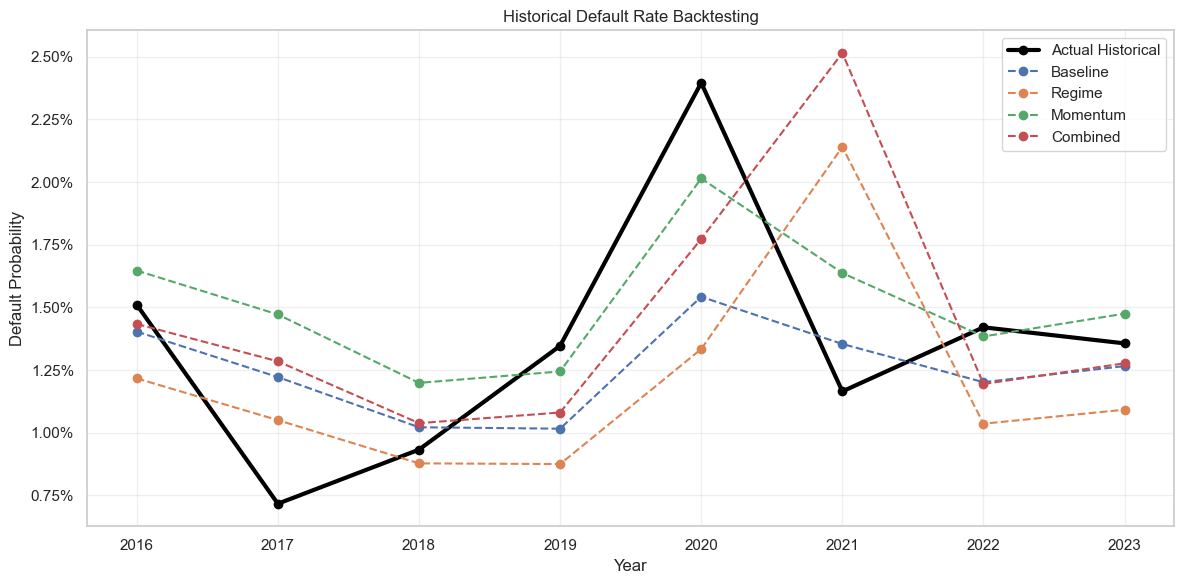

In [63]:
# Plot actual versus simulated historical default rates

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    historical_comparison.index,
    historical_comparison["Actual"],
    color="black",
    linewidth=3,
    marker="o",
    label="Actual Historical"
)

for model in BACKTEST_MODELS:

    ax.plot(
        historical_comparison.index,
        historical_comparison[model],
        linestyle="--",
        marker="o",
        label=model
    )

ax.set_title("Historical Default Rate Backtesting")
ax.set_xlabel("Year")
ax.set_ylabel("Default Probability")

ax.yaxis.set_major_formatter(
    plt.matplotlib.ticker.PercentFormatter(1)
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Predictive Performance Metrics

The models are evaluated using four statistical metrics.

- RMSE: Measures the discrepancy between simulated and
  actual annual default rates, penalizing larger errors.

- MAE: Measures the average absolute difference between
  simulated and actual annual default rates.

- Brier Score: Measures the accuracy of individual
  company-level default probabilities.

- Negative Log-Likelihood: Measures how much probability
  each model assigns to the credit rating transitions
  that actually occurred.

Lower values indicate better performance for all four
metrics.

The primary model ranking is based on historical default
rate RMSE.

In [64]:
# Evaluate and rank models by historical predictive performance

evaluation_records = []

for model, results in backtest_results.groupby("Model"):

    errors = results["Simulated PD"] - results["Actual PD"]

    exact_errors = results["Exact PD"] - results["Actual PD"]

    n_observations = results["Companies"].sum()

    evaluation_records.append({
        "Model": model,

        "RMSE": np.sqrt(np.mean(errors ** 2)),

        "MAE": np.mean(np.abs(errors)),

        "Exact RMSE": np.sqrt(np.mean(exact_errors ** 2)),

        "Brier Score": (
            results["Brier Sum"].sum() / n_observations
        ),

        "Mean NLL": (
            results["NLL Sum"].sum() / n_observations
        )
    })

model_ranking = (
    pd.DataFrame(evaluation_records)
    .set_index("Model")
    .sort_values("RMSE")
)

model_ranking.insert(
    0,
    "Rank",
    np.arange(1, len(model_ranking) + 1)
)

display(
    model_ranking.style.format({
        "RMSE": "{:.4%}",
        "MAE": "{:.4%}",
        "Exact RMSE": "{:.4%}",
        "Brier Score": "{:.6f}",
        "Mean NLL": "{:.6f}"
    })
)

print("Best-performing model by RMSE:", model_ranking.index[0])

,Rank,RMSE,MAE,Exact RMSE,Brier Score,Mean NLL
Model,,,,,,
Momentum,1,0.3630%,0.2836%,0.3643%,0.010501,0.349721
Baseline,2,0.3880%,0.2981%,0.3868%,0.010656,0.348717
Combined,3,0.5787%,0.4119%,0.5791%,0.010776,0.352041
Regime,4,0.5831%,0.4801%,0.5843%,0.010945,0.351049


Best-performing model by RMSE: Momentum


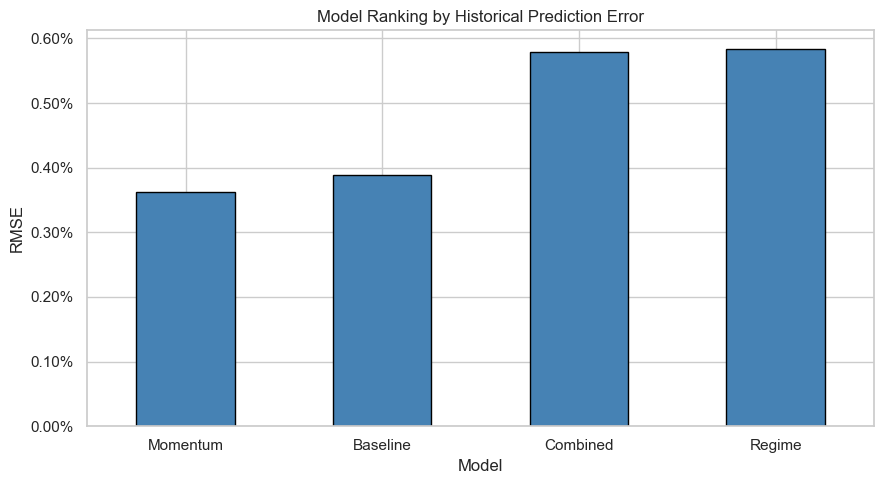

In [65]:
# Visualize the historical predictive performance ranking

ax = model_ranking["RMSE"].plot(
    kind="bar",
    figsize=(9, 5),
    color="steelblue",
    edgecolor="black"
)

ax.set_title("Model Ranking by Historical Prediction Error")
ax.set_xlabel("Model")
ax.set_ylabel("RMSE")

ax.yaxis.set_major_formatter(
    plt.matplotlib.ticker.PercentFormatter(1)
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [66]:
# Export historical evaluation results

backtest_results.to_csv(
    PROCESSED / "historical_backtest_results.csv",
    index=False
)

historical_comparison.to_csv(
    PROCESSED / "historical_default_comparison.csv"
)

model_ranking.to_csv(
    PROCESSED / "historical_model_ranking.csv"
)

#### Discussing differences between models

The four models differ primarily in the information used to determine credit rating transition probabilities.

- **Baseline model:** Assumes that future credit rating transitions depend solely on the current credit rating, with transition probabilities remaining constant over time.

- **Regime-dependent model:** Incorporates macroeconomic conditions, allowing transition probabilities to vary between expansionary and recessionary periods.

- **Momentum-dependent model:** Incorporates previous credit rating movements, allowing firms with identical current ratings to exhibit different transition probabilities based on their rating history.

- **Combined model:** Incorporates both economic regimes and rating momentum, providing the most detailed conditional representation of credit risk among the four models.

For an initially BB-rated firm, the analytical 20-year cumulative default probabilities were 32.85%, 31.58%, 34.91%, and 33.57%, respectively. These differences demonstrate that incorporating additional information can influence the estimated evolution of credit risk.

The sensitivity analysis further demonstrates that strengthening the multipliers generally increases medium- and long-term default probabilities under the selected initial conditions, despite slightly decreasing the one-year default probability. When the multiplier strength is set to zero, the baseline model is recovered, providing an additional mathematical consistency check.

Although the combined model provides the richest conditional representation, greater model complexity does not necessarily imply greater predictive accuracy. Establishing predictive superiority would require validation against independent historical credit rating observations.

#### Limitations of the baseline model
The baseline assumes homogeneous annual transitions and no dependence on past ratings beyond the current rating.

#### Limitations of economic multipliers
Regime multipliers use aggregate rating activity and a binary annual recession definition. The regime process is assumed time-homogeneous.

#### Limitations of momentum multipliers
Momentum multipliers are literature-derived and may not transfer perfectly across samples, agencies, or time periods.

#### Assumptions of the combined model
The combined model assumes multiplicative separability and does not estimate interactions from jointly labeled firm-level data.

### Final Conclusions

This project investigated how economic regimes and credit rating momentum can be incorporated into conventional Markov models of corporate credit rating transitions. Using historical S&P transition probabilities, FRED economic recession data, and conditional transition matrices from Bangia et al., four models were constructed and compared.

The results demonstrate that model-implied credit risk is influenced not only by a firm's current credit rating but also by economic conditions and previous rating movements. Recessionary conditions generally increase downgrade and default probabilities, while negative rating momentum is associated with greater subsequent credit deterioration. The combined model further illustrates that firms with identical credit ratings can exhibit substantially different default probabilities depending on their economic environment and rating history.

Historical backtesting was conducted using Fitch corporate credit rating observations from 2016 to 2023. The momentum-dependent model achieved the lowest default prediction RMSE of 0.3630%, representing a 6.44% reduction in prediction error relative to the baseline model. It also achieved the lowest MAE and Brier Score. However, the baseline model achieved the lowest negative log-likelihood, suggesting that it remains competitive when predicting overall credit rating transitions rather than defaults alone.

Interestingly, the regime-dependent and combined models performed worse than the baseline model in historical default prediction. Both models exhibited a delayed response to the economic shock of 2020, potentially attributable to the use of lagged economic regime information. These results demonstrate that incorporating additional information and increasing model complexity do not necessarily improve predictive accuracy.

From a stochastic processes perspective, the project demonstrates how state-space augmentation can incorporate historical dependence while preserving the Markov property of the augmented process. The close agreement between analytical and Monte Carlo results also supports the computational consistency of the proposed models.

Nevertheless, the study is limited by the relatively short historical evaluation period, differences between Fitch and S&P rating methodologies, potentially overlapping historical data, the use of US economic regimes as a proxy for global economic conditions, and the assumption of multiplicatively separable regime and momentum effects. Future research could address these limitations through longer evaluation periods, more responsive economic indicators, rating-specific multipliers, statistical significance testing, and strictly out-of-sample validation.

Overall, the findings suggest that credit rating momentum provides useful additional information for default prediction, while economic regime dependence requires a more responsive formulation. Although the combined model provides the most granular representation of corporate credit risk, it does not achieve the strongest historical predictive performance. The results highlight the importance of balancing model complexity, interpretability, and empirical predictive accuracy when developing stochastic credit risk models.

#### Potential extensions
firm-level validation, joint interaction estimation, alternative macro indicators and uncertainty quantification.

#### References
S&P Global Annual Global Corporate Default and Rating Transition Study (exact edition); FRED USREC (https://fred.stlouisfed.org/series/USREC); Bangia et al